# Chapitre 15 - Forêts aléatoires (2) : importance, proximités, analyse biais/variance

Ce second notebook couvre les sections 15.3.2 à 15.4 du livre :

1. l'**importance des variables** (critère de Gini et permutation OOB, figure 15.5) ;
2. les **graphiques de proximité** (figure 15.6) ;
3. le rôle des variables de bruit et de la profondeur des arbres (sur-apprentissage,
   figure 15.8) ;
4. l'**analyse de la variance et du biais** d'une forêt en fonction de $m$
   (figures 15.9 et 15.10) et le lien avec la régression ridge ;
5. la forêt vue comme un **plus proche voisin adaptatif** (figure 15.11).

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import datasets
from esl import ch15_forets as rf
set_style()

## 1. Réglages par défaut (section 15.3)

Les inventeurs des forêts recommandent :

| tâche | $m$ par défaut | effectif minimal des feuilles $n_{\min}$ |
|---|---|---|
| classification | $\lfloor\sqrt p\rfloor$ | 1 |
| régression | $\lfloor p/3\rfloor$ | 5 |

Ce ne sont que des points de départ : $m$ et $n_{\min}$ sont des **paramètres de
réglage**, que l'on choisit par exemple en minimisant l'erreur OOB (voir l'exercice 15.6).

## 2. Importance des variables (section 15.3.2)

Deux mesures sont classiques.

**Importance « Gini ».** À chaque coupure d'un arbre, le critère (indice de Gini ou somme
des carrés) diminue d'une certaine quantité ; on attribue cette diminution à la variable
utilisée pour couper, et l'on somme sur tous les nœuds de tous les arbres. C'est la même
construction que pour le boosting (section 10.13).

**Importance par permutation OOB.** Pour l'arbre $b$, on mesure la précision sur ses
observations hors sac ; on **permute aléatoirement** les valeurs de la variable $j$ parmi
ces observations et l'on mesure à nouveau la précision. La baisse de précision, moyennée
sur les arbres, mesure l'importance de $X_j$.

> **Intuition.** Permuter la colonne $j$ conserve sa loi marginale mais détruit son lien
> avec $Y$ (et avec les autres variables) : c'est un peu comme mettre à zéro le
> coefficient de $X_j$ dans un modèle linéaire (exercice 15.7). Ce n'est **pas** la perte
> que l'on subirait en réajustant le modèle sans $X_j$ : d'autres variables corrélées
> pourraient alors la remplacer.

Ajustons notre forêt « maison » sur les données spam ($B=200$, $m=7$).

In [2]:
spam = datasets.load_spam()
Xtr, ytr, Xte, yte = rf.separer_spam(spam)
noms = np.array(rf.NOMS_SPAM)

t0 = time.time()
foret = rf.ForetAleatoire(B=200, m=7, nmin=1, classification=True, seed=0).fit(Xtr, ytr)
print("ajustement : %.0f s, erreur test : %.4f" % (time.time() - t0, np.mean(foret.predict(Xte) != yte)))

ajustement : 6 s, erreur test : 0.0469


In [3]:
t0 = time.time()
imp_gini = foret.importance_gini
imp_perm = rf.importance_permutation(foret, Xtr, ytr, seed=0)
imp_perm_pct = 100 * imp_perm / imp_perm.max()
print("permutations : %.0f s" % (time.time() - t0))
print("5 variables les plus importantes (Gini)        :", ", ".join(noms[np.argsort(-imp_gini)[:5]]))
print("5 variables les plus importantes (permutation) :", ", ".join(noms[np.argsort(-imp_perm)[:5]]))

permutations : 2 s
5 variables les plus importantes (Gini)        : !, remove, $, CAPAVE, free
5 variables les plus importantes (permutation) : !, remove, CAPMAX, hp, CAPTOT


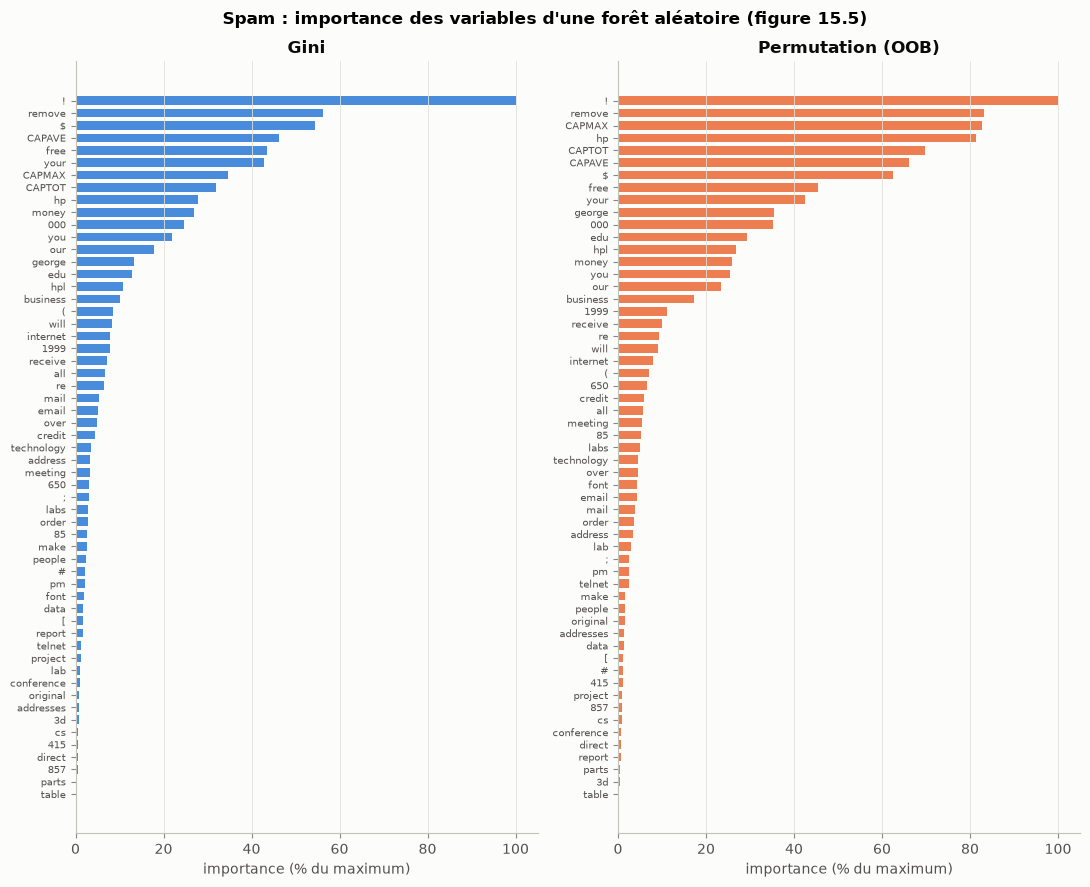

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 9))
for ax, imp, titre, c in [(axes[0], imp_gini, "Gini", BLUE), (axes[1], imp_perm_pct, "Permutation (OOB)", ORANGE)]:
    ordre = np.argsort(imp)
    ax.barh(np.arange(len(imp)), imp[ordre], color=c, alpha=0.85, height=0.7)
    ax.set_yticks(np.arange(len(imp)), noms[ordre], fontsize=7)
    ax.set_xlabel("importance (% du maximum)")
    ax.set_title(titre)
    ax.grid(axis="y", visible=False)
fig.suptitle("Spam : importance des variables d'une forêt aléatoire (figure 15.5)", fontweight="bold")
plt.tight_layout()
plt.show()

On retrouve les variables du livre en tête (« ! », « $ », « remove », « free », les
longueurs de suites de majuscules CAPAVE/CAPMAX/CAPTOT, « hp »…). Les deux classements
sont proches, mais la mesure par permutation **répartit l'importance plus uniformément**.
Comparons les rangs :

In [5]:
from scipy.stats import spearmanr
print("corrélation de Spearman entre les deux importances : %.3f" % spearmanr(imp_gini, imp_perm).correlation)
print("variables d'importance Gini < 5 %% : %d ; d'importance permutation < 5 %% : %d"
      % (np.sum(imp_gini < 5), np.sum(imp_perm_pct < 5)))

corrélation de Spearman entre les deux importances : 0.961
variables d'importance Gini < 5 % : 31 ; d'importance permutation < 5 % : 29


> **Remarque.** Contrairement au boosting (figure 10.6), la forêt n'ignore presque aucune
> variable : le tirage des $m$ candidates donne régulièrement leur chance à des variables
> faibles, qui sont alors choisies faute de mieux.

## 3. Graphiques de proximité (section 15.3.3)

Pendant la construction de la forêt, on accumule une matrice $N\times N$ de
**proximités** : pour chaque arbre, toute paire d'observations OOB qui tombent dans la
**même feuille** voit sa proximité augmenter de 1 (nous normalisons ensuite par le nombre
d'arbres où les deux observations sont OOB, pour obtenir une proximité
$P_{ii'}\in[0,1]$).

On représente ensuite ces proximités dans le plan par **positionnement multidimensionnel**
(MDS, section 14.8) appliqué aux dissimilarités $1-P_{ii'}$.

### Rappel : le MDS classique

Étant donné des dissimilarités $d_{ii'}$, on cherche des points $z_1,\dots,z_N\in\mathbb R^2$
dont les distances euclidiennes reproduisent au mieux les $d_{ii'}$. Si les $d_{ii'}$ sont
exactement des distances euclidiennes entre points centrés, la matrice des produits
scalaires $\mathbf B=(\langle z_i,z_{i'}\rangle)$ s'obtient par **double centrage** :
$\mathbf B=-\frac12\mathbf J\mathbf D^{(2)}\mathbf J$, où $\mathbf D^{(2)}=(d_{ii'}^2)$ et
$\mathbf J=\mathbf I-\frac1N\mathbf 1\mathbf 1^T$. On garde alors les deux premiers vecteurs
propres de $\mathbf B$, multipliés par la racine de leurs valeurs propres (fonction
`mds_classique`).

### Les données « mixture »

Comme dans le livre, nous utilisons les données simulées du chapitre 2 (200 points dans
le plan, deux classes). En dimension 2, $m=\lfloor\sqrt2\rfloor=1$.

In [6]:
mix = datasets.load_mixture_example()
Xm, ym = mix["x"], mix["y"]
foret_mix = rf.ForetAleatoire(B=500, m=1, nmin=1, classification=True, seed=0).fit(Xm, ym)
Prox = rf.proximite(foret_mix.feuilles(Xm), foret_mix.dans_sac)
Zmds = rf.mds_classique(np.sqrt(1 - Prox), k=2)
print("proximité moyenne entre deux points de même classe : %.3f" % Prox[ym[:, None] == ym[None, :]].mean())
print("proximité moyenne entre deux points de classes différentes : %.3f" % Prox[ym[:, None] != ym[None, :]].mean())

proximité moyenne entre deux points de même classe : 0.103
proximité moyenne entre deux points de classes différentes : 0.036


Choisissons six points repères : pour chaque classe, le point le plus éloigné du centre
du graphique MDS (extrémité d'une « branche »), le point le plus proche du centre, et un
point à distance médiane.

In [7]:
rayon = np.linalg.norm(Zmds - Zmds.mean(0), axis=1)
reperes = []
for regle in (np.argmax, np.argmin, None):
    for k in (0, 1):
        idx = np.flatnonzero(ym == k)
        if regle is None:
            j = idx[np.argmin(np.abs(rayon[idx] - np.median(rayon[idx])))]
        else:
            j = idx[regle(rayon[idx])]
        reperes.append(int(j))
print("indices des repères :", reperes)

indices des repères : [23, 179, 66, 156, 55, 174]


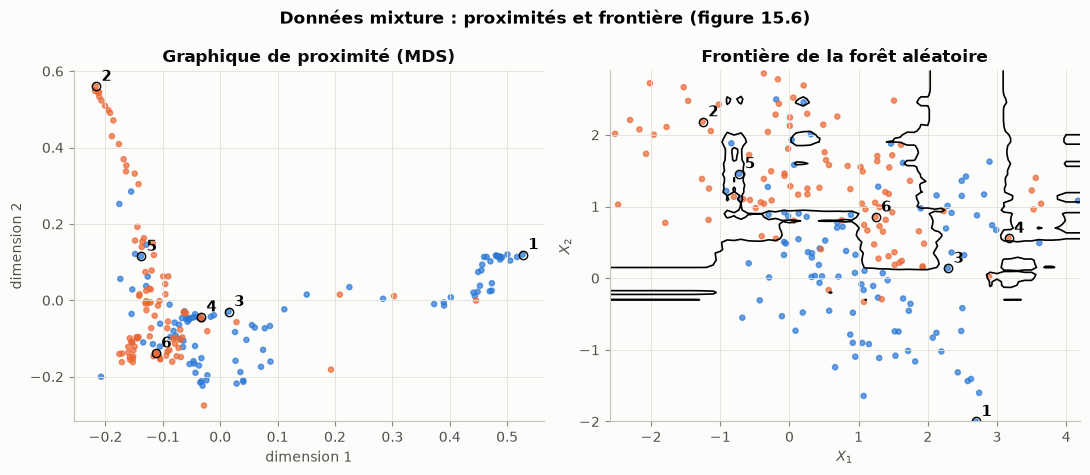

In [8]:
xx, yy = mix["px1"], mix["px2"]
grille = mix["xnew"]
vote = foret_mix.predictions_arbres(grille).mean(0)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
ax = axes[0]
ax.scatter(Zmds[:, 0], Zmds[:, 1], c=ym, cmap=TWO_CLASS, s=14, alpha=0.7)
ax.set_title("Graphique de proximité (MDS)")
ax.set_xlabel("dimension 1")
ax.set_ylabel("dimension 2")
ax = axes[1]
ax.contour(xx, yy, vote.reshape(len(yy), len(xx)), levels=[0.5], colors="k", linewidths=1.2)
ax.scatter(Xm[:, 0], Xm[:, 1], c=ym, cmap=TWO_CLASS, s=14, alpha=0.7)
ax.set_title("Frontière de la forêt aléatoire")
ax.set_xlabel("$X_1$")
ax.set_ylabel("$X_2$")
for k, i in enumerate(reperes, 1):
    for ax, pts in zip(axes, (Zmds, Xm)):
        ax.annotate(str(k), pts[i], fontsize=11, fontweight="bold", color="k",
                    xytext=(4, 4), textcoords="offset points")
        ax.plot(*pts[i], "ko", ms=6, mfc="none")
fig.suptitle("Données mixture : proximités et frontière (figure 15.6)", fontweight="bold")
plt.tight_layout()
plt.show()

Le graphique de proximité a la forme d'**étoile** typique, une branche par classe. Les
points des extrémités (repères 1 et 2) sont situés dans des régions **pures** du plan :
des voisins de même classe y partagent très souvent une feuille, car un nœud pur n'est
plus coupé. Les points proches du centre (repères 3 et 4) sont en général près de la
frontière de décision, où des voisins de classes différentes ne partagent une feuille que de temps
en temps.

La même construction sur un échantillon de 500 courriels spam (proximités issues de la
forêt de la section 2) donne encore une étoile à deux branches, ce qui illustre la
remarque du livre : ces graphiques se ressemblent beaucoup d'un jeu de données à l'autre.

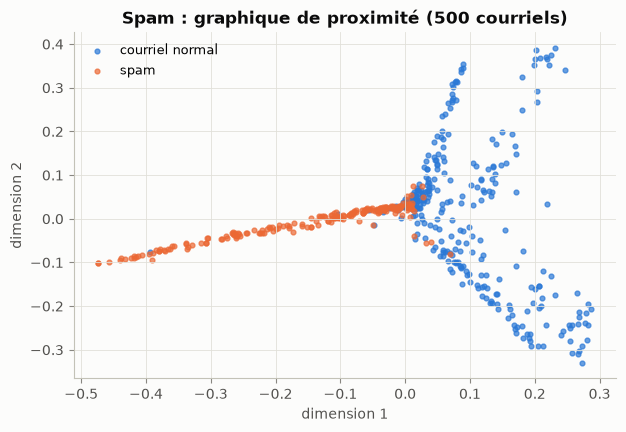

In [9]:
rng = np.random.RandomState(0)
sous = rng.choice(len(ytr), 500, replace=False)
Prox_spam = rf.proximite(foret.feuilles(Xtr[sous]), foret.dans_sac[:, sous])
Z_spam = rf.mds_classique(np.sqrt(1 - Prox_spam), k=2)

fig, ax = plt.subplots(figsize=(7, 4.5))
for k, nom in enumerate(["courriel normal", "spam"]):
    sel = ytr[sous] == k
    ax.scatter(Z_spam[sel, 0], Z_spam[sel, 1], s=12, color=COLORS[k], alpha=0.7, label=nom)
ax.set_xlabel("dimension 1")
ax.set_ylabel("dimension 2")
ax.set_title("Spam : graphique de proximité (500 courriels)")
ax.legend()
plt.show()

## 4. Forêts et sur-apprentissage (section 15.3.4)

**Variables de bruit.** Si $p$ est grand mais que peu de variables sont pertinentes, un
petit $m$ risque de ne proposer, à une coupure donnée, **aucune** variable pertinente. Si
$J$ variables sont pertinentes parmi $p$ et que l'on en tire $m$ sans remise, la
probabilité d'en avoir au moins une est (loi hypergéométrique)
$$1-\binom{p-J}{m}\Big/\binom{p}{m}.$$

In [10]:
for bruit in (5, 25, 50, 100, 150):
    p_ = 2 + bruit
    m_ = int(np.sqrt(p_))
    print("J = 2 pertinentes, %3d de bruit, m = %2d : probabilité = %.2f"
          % (bruit, m_, rf.proba_variable_pertinente(p_, 2, m_)))

J = 2 pertinentes,   5 de bruit, m =  2 : probabilité = 0.52
J = 2 pertinentes,  25 de bruit, m =  5 : probabilité = 0.34
J = 2 pertinentes,  50 de bruit, m =  7 : probabilité = 0.25
J = 2 pertinentes, 100 de bruit, m = 10 : probabilité = 0.19
J = 2 pertinentes, 150 de bruit, m = 12 : probabilité = 0.15


Ce sont les valeurs affichées en haut de la figure 15.7 (étudiée dans l'exercice 15.3).
Avec $J=6$ pertinentes et 100 de bruit, $m=\lfloor\sqrt{106}\rfloor=10$ donne une
probabilité de

In [11]:
print("%.2f" % rf.proba_variable_pertinente(106, 6, 10))

0.46


**« Les forêts ne sur-apprennent pas ».** Il est vrai qu'augmenter $B$ ne provoque pas de
sur-apprentissage : $\hat f^B_{\rm rf}(x)$ converge vers l'espérance
$\hat f_{\rm rf}(x)=\mathbb E_\Theta T(x;\Theta)$ (éq. (15.3)), l'espérance étant prise sur
l'aléa $\Theta$ (bootstrap et tirage des variables), conditionnellement aux données. Mais
cette **limite** peut elle-même sur-apprendre : une moyenne d'arbres très profonds peut
être un modèle trop riche. On peut contrôler la profondeur via l'effectif minimal des
feuilles $n_{\min}$.

Reproduisons l'esprit de la figure 15.8 : régression avec $p=12$ variables gaussiennes,
une vraie fonction additive en deux variables (nous prenons
$f(x)=x_1+\sin(2x_2)$, le livre ne précisant pas la sienne) et un bruit gaussien de
variance 1. Nous utilisons scikit-learn (`RandomForestRegressor`, $m=4$, 200 arbres) pour
répéter l'expérience 10 fois par valeur de $n_{\min}$.

In [12]:
from sklearn.ensemble import RandomForestRegressor

def simu_fig158(N, rng):
    X = rng.randn(N, 12)
    f = X[:, 0] + np.sin(2 * X[:, 1])
    return X, f + rng.randn(N), f

tailles = [50, 30, 20, 10, 5, 1]
rng = np.random.RandomState(0)
mse_noeud = np.zeros((10, len(tailles)))
Xt158, yt158, ft158 = simu_fig158(2000, rng)
for r in range(10):
    X, y, _ = simu_fig158(300, rng)
    for k, nm in enumerate(tailles):
        mod = RandomForestRegressor(200, max_features=4, min_samples_leaf=nm, n_jobs=-1, random_state=r).fit(X, y)
        mse_noeud[r, k] = np.mean((mod.predict(Xt158) - yt158) ** 2)

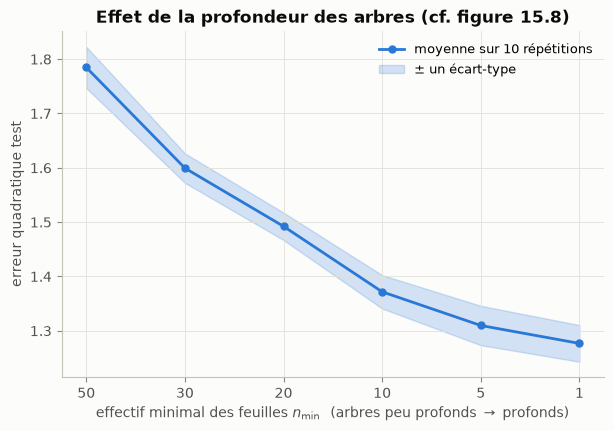

In [13]:
fig, ax = plt.subplots(figsize=(7, 4.5))
pos = np.arange(len(tailles))
ax.plot(pos, mse_noeud.mean(0), "o-", color=BLUE, label="moyenne sur 10 répétitions")
ax.fill_between(pos, mse_noeud.mean(0) - mse_noeud.std(0), mse_noeud.mean(0) + mse_noeud.std(0),
                color=BLUE, alpha=0.2, label="± un écart-type")
ax.set_xticks(pos, tailles)
ax.set_xlabel(r"effectif minimal des feuilles $n_{\min}$  (arbres peu profonds $\rightarrow$ profonds)")
ax.set_ylabel("erreur quadratique test")
ax.set_title("Effet de la profondeur des arbres (cf. figure 15.8)")
ax.legend()
plt.show()

L'effet est **modeste** (l'erreur reste dominée par la variance du bruit, égale à 1) :
des arbres de profondeur intermédiaire font un peu mieux, mais utiliser des arbres
complets coûte peu. En classification, cet effet est encore plus rarement visible.

## 5. Analyse de la variance (section 15.4.1)

Plaçons-nous en régression, en un point cible $x$ fixé. Notons $\mathbf Z$ l'échantillon
d'apprentissage (aléatoire) et $\Theta$ l'aléa propre à un arbre (bootstrap + tirage des
variables). La forêt « limite » ($B\to\infty$) est
$$\hat f_{\rm rf}(x)=\mathbb E_{\Theta\mid\mathbf Z}\,T(x;\Theta(\mathbf Z))\qquad\text{(15.4)}.$$
D'après (15.1) avec $B\to\infty$, sa variance vaut
$$\operatorname{Var}\hat f_{\rm rf}(x)=\rho(x)\,\sigma^2(x)\qquad\text{(15.5)},$$
avec $\sigma^2(x)=\operatorname{Var}T(x;\Theta(\mathbf Z))$ la variance d'un arbre et
$\rho(x)$ la corrélation entre deux arbres construits sur **le même** $\mathbf Z$ avec des
aléas $\Theta_1,\Theta_2$ indépendants, la variabilité venant à la fois de $\mathbf Z$ et
de $\Theta$.

> **Attention.** $\rho(x)$ n'est **pas** la corrélation moyenne entre les arbres d'une
> forêt déjà ajustée (vus comme des vecteurs de prédictions) : c'est une corrélation
> théorique, induite par le tirage répété d'échantillons $\mathbf Z$ dans la population.
> Conditionnellement à $\mathbf Z$, deux arbres sont même **indépendants** (exercice 15.5).

La formule de la variance totale (variance conditionnelle) donne la décomposition (15.9) :
$$
\underbrace{\operatorname{Var}_{\Theta,\mathbf Z}T(x;\Theta(\mathbf Z))}_{\text{variance totale}}
=\underbrace{\operatorname{Var}_{\mathbf Z}\,\mathbb E_{\Theta\mid\mathbf Z}T(x;\Theta(\mathbf Z))}_{=\operatorname{Var}_{\mathbf Z}\hat f_{\rm rf}(x)}
+\underbrace{\mathbb E_{\mathbf Z}\operatorname{Var}_{\Theta\mid\mathbf Z}T(x;\Theta(\mathbf Z))}_{\text{variance « intra-}\mathbf Z\text{ »}} ,
$$
et l'exercice 15.5 montre que $\rho(x)$ est le rapport du premier terme à la variance
totale (formule (15.12)).

### Le modèle de simulation (15.8)

$$Y=\frac1{\sqrt{50}}\sum_{j=1}^{50}X_j+\varepsilon,$$
avec les $X_j$ et $\varepsilon$ i.i.d. $\mathcal N(0,1)$. Le livre utilise 500
échantillons d'apprentissage de taille 100 et 600 points test ; nous prenons 60
échantillons et 40 arbres par forêt, et utilisons `RandomForestRegressor` de scikit-learn
($n_{\min}=5$) pour ajuster les 1500 forêts en un temps raisonnable. Pour chaque $m$, nous
gardons le tableau des prédictions `T[z, t, i]` (échantillon $z$, arbre $t$, point $x_i$),
que la fonction `decomposition_variance` résume.

> **Remarque (correction pour $B$ fini).** Avec seulement 40 arbres, la moyenne
> $\bar T_z(x)$ des arbres du $z$-ième échantillon n'est qu'une approximation de
> $\hat f_{\rm rf}(x)$ : conditionnellement à $\mathbf Z$, sa variance vaut
> $\operatorname{Var}_{\Theta\mid\mathbf Z}T/40$ (formule (15.1) avec $\rho=0$). La variance
> empirique des $\bar T_z(x)$ surestime donc $\operatorname{Var}_{\mathbf Z}\hat f_{\rm rf}(x)$
> d'environ « intra / 40 », terme que nous retranchons.

In [14]:
from sklearn.tree import DecisionTreeRegressor

rng = np.random.RandomState(0)
Xtest, _, mu_test = rf.simuler_additif(600, rng=rng)
echantillons = [rf.simuler_additif(100, rng=rng)[:2] for _ in range(150)]
m_grille = [1, 4, 7, 13, 19, 25, 31, 37, 43, 49]

t0 = time.time()
decomp = {}
for m in m_grille:
    T = np.empty((len(echantillons), 40, len(Xtest)))
    for z, (X, y) in enumerate(echantillons):
        mod = RandomForestRegressor(40, max_features=m, min_samples_leaf=5, n_jobs=1, random_state=z).fit(X, y)
        T[z] = [e.predict(Xtest) for e in mod.estimators_]
    decomp[m] = rf.decomposition_variance(T, mu_test)
print("temps : %.0f s" % (time.time() - t0))

temps : 32 s


Référence : un arbre unique, ajusté sur tout l'échantillon (sans bootstrap, toutes les
variables candidates), avec le même $n_{\min}=5$.

In [15]:
T_seul = np.array([DecisionTreeRegressor(min_samples_leaf=5, random_state=0).fit(X, y).predict(Xtest)
                   for X, y in echantillons])
var_seul = T_seul.var(axis=0, ddof=1).mean()
biais2_seul = ((T_seul.mean(axis=0) - mu_test) ** 2).mean()
print("arbre seul : variance moyenne %.3f, biais au carré moyen %.3f" % (var_seul, biais2_seul))

arbre seul : variance moyenne 1.490, biais au carré moyen 0.693


### Corrélation entre arbres (figure 15.9)

Pour chaque $m$, la distribution sur les 600 points test de $\hat\rho(x)$ :

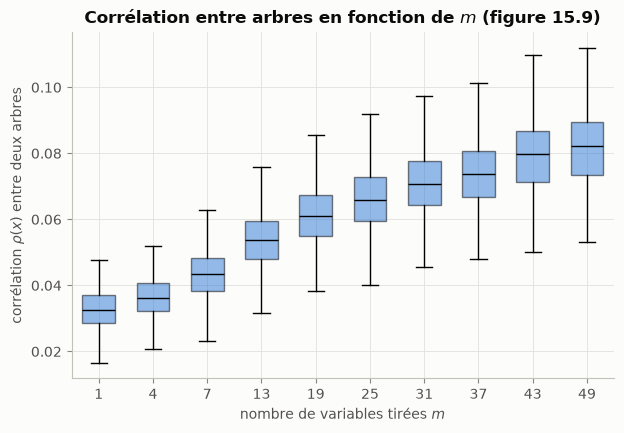

In [16]:
fig, ax = plt.subplots(figsize=(7, 4.5))
bp = ax.boxplot([decomp[m]["rho"] for m in m_grille], patch_artist=True, widths=0.6, showfliers=False)
for patch in bp["boxes"]:
    patch.set_facecolor(BLUE)
    patch.set_alpha(0.5)
for med_ in bp["medians"]:
    med_.set_color("k")
ax.set_xticks(range(1, len(m_grille) + 1), m_grille)
ax.set_xlabel("nombre de variables tirées $m$")
ax.set_ylabel(r"corrélation $\rho(x)$ entre deux arbres")
ax.set_title("Corrélation entre arbres en fonction de $m$ (figure 15.9)")
plt.show()

Plus $m$ est petit, plus deux arbres construits sur le même échantillon sont
**décorrélés** : ils utilisent rarement les mêmes variables de coupure. Les ordres de
grandeur ($\rho$ de quelques centièmes) sont ceux du livre. Notre estimation de $\rho(x)$,
fondée sur 150 échantillons au lieu de 500, est plus bruitée.

### Variance et biais (figure 15.10)

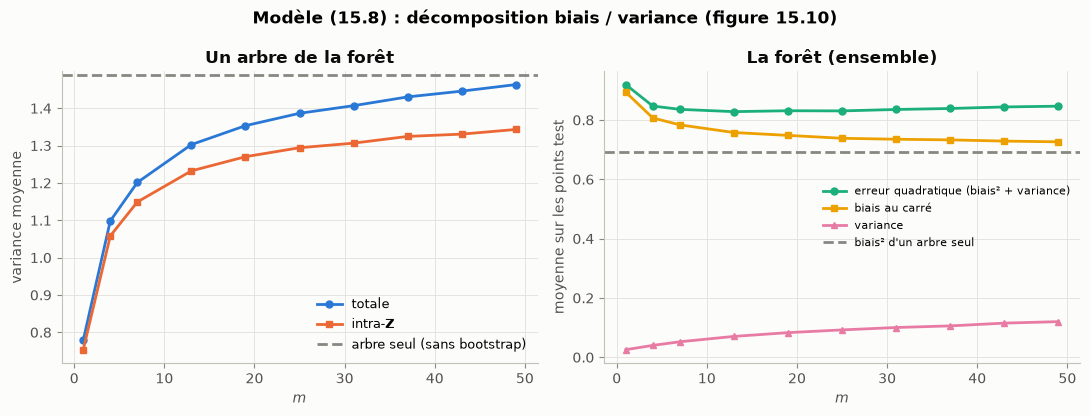

In [17]:
moy = lambda cle: np.array([decomp[m][cle].mean() for m in m_grille])
totale, intra, var_rf, biais2 = moy("totale"), moy("intra"), moy("var_rf"), moy("biais2")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
ax = axes[0]
ax.plot(m_grille, totale, "o-", color=BLUE, label="totale")
ax.plot(m_grille, intra, "s-", color=ORANGE, label=r"intra-$\mathbf{Z}$")
ax.axhline(var_seul, color=GRAY, ls="--", label="arbre seul (sans bootstrap)")
ax.set_xlabel("$m$")
ax.set_ylabel("variance moyenne")
ax.set_title("Un arbre de la forêt")
ax.legend()
ax = axes[1]
ax.plot(m_grille, biais2 + var_rf, "o-", color=COLORS[2], label="erreur quadratique (biais² + variance)")
ax.plot(m_grille, biais2, "s-", color=COLORS[3], label="biais au carré")
ax.plot(m_grille, var_rf, "^-", color=COLORS[4], label="variance")
ax.axhline(biais2_seul, color=GRAY, ls="--", label="biais² d'un arbre seul")
ax.set_xlabel("$m$")
ax.set_ylabel("moyenne sur les points test")
ax.set_title("La forêt (ensemble)")
ax.legend(fontsize=8)
fig.suptitle("Modèle (15.8) : décomposition biais / variance (figure 15.10)", fontweight="bold")
plt.tight_layout()
plt.show()

Lecture des deux panneaux :

- **à gauche**, la variance d'un arbre individuel est dominée par sa part
  « intra-$\mathbf Z$ » (due à l'aléa $\Theta$), dont la **proportion** augmente quand
  $m$ diminue. Dans notre simulation la variance totale d'un arbre diminue aussi nettement quand
  $m$ diminue (un arbre qui coupe sur des variables tirées au hasard est plus « plat »,
  donc moins variable), alors qu'elle est plus stable dans le livre ; dans tous les cas
  elle reste du même ordre que celle d'un arbre seul ;
- **à droite**, la variance de la forêt, $\operatorname{Var}_{\mathbf Z}\hat f_{\rm rf}=$
  totale $-$ intra, **diminue** quand $m$ diminue, alors que le **biais augmente** : on a un
  compromis biais/variance classique en $m$. Pour tout $m$, le biais de la forêt dépasse
  celui d'un arbre seul (ligne en tirets).

In [18]:
i_opt = int(np.argmin(biais2 + var_rf))
print("m optimal sur la grille : %d (erreur %.3f)" % (m_grille[i_opt], (biais2 + var_rf)[i_opt]))
print("rapport variance forêt / variance arbre : de %.3f (m=1) à %.3f (m=49)"
      % (var_rf[0] / totale[0], var_rf[-1] / totale[-1]))

m optimal sur la grille : 13 (erreur 0.828)
rapport variance forêt / variance arbre : de 0.033 (m=1) à 0.082 (m=49)


## 6. Biais et analogie avec la régression ridge (section 15.4.2)

Comme pour le bagging, le biais de la forêt est celui d'un arbre de la forêt :
$$\operatorname{Biais}(x)=\mu(x)-\mathbb E_{\mathbf Z}\hat f_{\rm rf}(x)=\mu(x)-\mathbb E_{\mathbf Z}\mathbb E_{\Theta\mid\mathbf Z}T(x;\Theta(\mathbf Z))\qquad\text{(15.10)},$$
où $\mu(x)=\mathbb E(Y\mid X=x)$. Il est en général plus grand (en valeur absolue) que celui
d'un arbre non élagué ajusté sur $\mathbf Z$ : bootstrap et restriction des variables
contraignent l'arbre. **Toute l'amélioration vient donc de la réduction de variance.**

Un petit $m$ joue un rôle analogue à la **régression ridge** (section 3.4.1) : chaque
variable pertinente a sa chance d'être la variable de coupure principale, et la moyenne
réduit la contribution de chacune, comme ridge rétrécit des coefficients de tailles
comparables. Le modèle (15.8) étant linéaire, ridge y est d'ailleurs bien meilleur :

In [19]:
lambdas = np.logspace(-1, 3, 40)
err_ridge = np.zeros(len(lambdas))
ddl = np.zeros(len(lambdas))
for X, y in echantillons:
    U, d, Vt = np.linalg.svd(X, full_matrices=False)
    for k, lam in enumerate(lambdas):
        beta = Vt.T @ (d / (d ** 2 + lam) * (U.T @ y))
        err_ridge[k] += np.mean((Xtest @ beta - mu_test) ** 2) / len(echantillons)
        ddl[k] += np.sum(d ** 2 / (d ** 2 + lam)) / len(echantillons)
k_opt = int(np.argmin(err_ridge))
print("ridge : erreur (biais² + variance) minimale %.3f pour df(lambda) = %.1f"
      % (err_ridge[k_opt], ddl[k_opt]))
print("meilleure forêt : %.3f" % (biais2 + var_rf).min())

ridge : erreur (biais² + variance) minimale 0.420 pour df(lambda) = 30.0
meilleure forêt : 0.828


On retrouve l'ordre de grandeur du livre (environ 0,45 avec $\mathrm{df}(\lambda)\approx29$),
nettement mieux que la forêt : quand la vraie fonction est linéaire, un modèle linéaire
régularisé est imbattable.

## 7. La forêt comme plus proches voisins adaptatifs (section 15.4.3)

Un arbre poussé jusqu'au bout prédit en $x$ la réponse d'**une** observation
d'apprentissage (ou de quelques-unes) : celle de la feuille où tombe $x$. La moyenne de
la forêt est donc une **moyenne pondérée des réponses d'apprentissage**, avec des poids
d'autant plus grands que l'observation partage souvent la feuille de $x$ : une sorte de
$k$ plus proches voisins dont le voisinage est choisi adaptativement par les arbres.
Comparons la forêt et les 3 plus proches voisins sur les données mixture (figure 15.11).

In [20]:
def knn_predict(Xa, ya, Xb, k=3):
    """k plus proches voisins (vote majoritaire), distances euclidiennes."""
    d2 = ((Xb[:, None, :] - Xa[None, :, :]) ** 2).sum(-1)
    voisins = np.argsort(d2, axis=1)[:, :k]
    return (ya[voisins].mean(1) > 0.5).astype(int)

rng = np.random.RandomState(1)
Xtm, ytm = rf.simuler_melange(mix["means"], 10000, rng)

def densite(X, centres):
    d2 = ((X[:, None, :] - centres[None]) ** 2).sum(-1)
    return np.exp(-2.5 * d2).sum(1)

bayes_test = (densite(Xtm, mix["means"][10:]) > densite(Xtm, mix["means"][:10])).astype(int)
erreurs = {
    "Forêt aléatoire": (np.mean(foret_mix.predict(Xm) != ym), np.mean(foret_mix.predict(Xtm) != ytm)),
    "3 plus proches voisins": (np.mean(knn_predict(Xm, ym, Xm) != ym),
                               np.mean(knn_predict(Xm, ym, Xtm) != ytm)),
}
err_bayes = np.mean(bayes_test != ytm)
for nom, (ea, et) in erreurs.items():
    print("%-24s apprentissage %.3f   test %.3f" % (nom, ea, et))
print("erreur de Bayes (estimée sur 10 000 points) : %.3f" % err_bayes)

Forêt aléatoire          apprentissage 0.000   test 0.237
3 plus proches voisins   apprentissage 0.130   test 0.241
erreur de Bayes (estimée sur 10 000 points) : 0.206


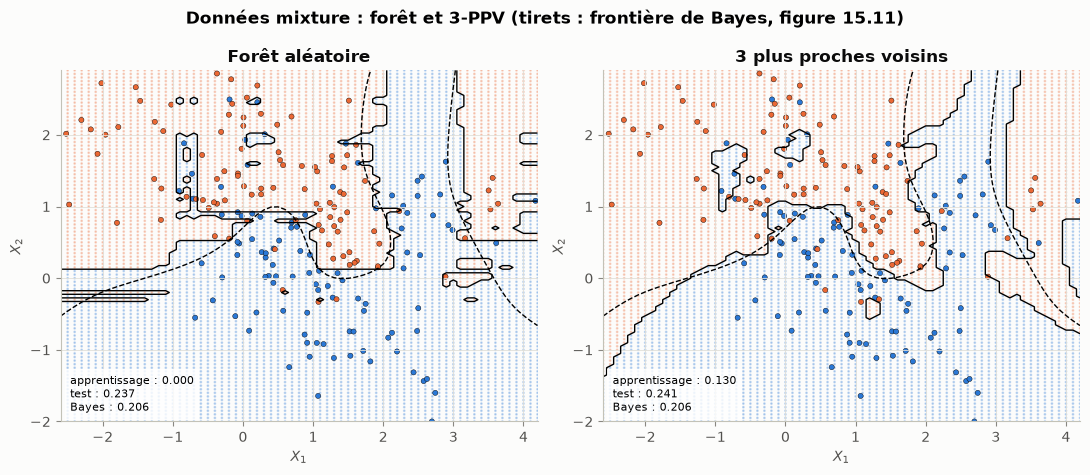

In [21]:
pred_knn = knn_predict(Xm, ym, grille)
pred_rf = (vote > 0.5).astype(int)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
for ax, pred, nom in zip(axes, (pred_rf, pred_knn), erreurs):
    ax.scatter(grille[:, 0], grille[:, 1], c=pred, cmap=TWO_CLASS, s=1, alpha=0.25)
    ax.contour(xx, yy, pred.reshape(len(yy), len(xx)), levels=[0.5], colors="k", linewidths=1)
    ax.contour(xx, yy, mix["prob"].reshape(len(yy), len(xx)), levels=[0.5], colors="k",
               linestyles="--", linewidths=1)
    ax.scatter(Xm[:, 0], Xm[:, 1], c=ym, cmap=TWO_CLASS, s=14, edgecolor="k", linewidth=0.3)
    ea, et = erreurs[nom]
    ax.text(0.02, 0.02, "apprentissage : %.3f\ntest : %.3f\nBayes : %.3f" % (ea, et, err_bayes),
            transform=ax.transAxes, fontsize=8, va="bottom",
            bbox=dict(facecolor="white", alpha=0.8, edgecolor="none"))
    ax.set_title(nom)
    ax.set_xlabel("$X_1$")
    ax.set_ylabel("$X_2$")
fig.suptitle("Données mixture : forêt et 3-PPV (tirets : frontière de Bayes, figure 15.11)",
             fontweight="bold")
plt.tight_layout()
plt.show()

Les deux frontières sont semblables et les erreurs test très proches ; celle de la
forêt a une allure **parallèle aux axes**, héritée des coupures des arbres. L'erreur
d'apprentissage de la forêt est nulle (arbres complets), ce qui ne l'empêche pas de bien
généraliser.

## Bilan

> **À retenir.**
> - Deux mesures d'importance : réduction cumulée du critère de coupure (Gini) et baisse
>   de précision OOB après permutation ; la seconde est plus uniforme.
> - Les proximités (partage de feuilles par des observations OOB) donnent une
>   représentation des données « vue par la forêt », souvent en étoile.
> - $\operatorname{Var}\hat f_{\rm rf}(x)=\rho(x)\sigma^2(x)$ : diminuer $m$ décorrèle les
>   arbres et réduit la variance de la forêt, mais augmente le biais ; $m$ règle un
>   compromis biais/variance.
> - Le biais d'une forêt est celui d'un de ses arbres ; le gain ne vient que de la
>   variance.
> - Une forêt se comporte comme un plus proche voisin à voisinage adaptatif.